In [1]:
%load_ext autoreload
%autoreload 2

from matplotlib import pyplot as plt
import numpy as np
from helpers import *
import math
import scipy

### Naloga 1. Zveza med Bernsteinovo in potenčno bazo

In [2]:
p = np.array([4,7,2,8,9,1,4]) # koeficienti od x^n do 1

b = power2bernstein(p)
b

array([ 4.        ,  4.16666667,  4.93333333,  6.7       , 10.        ,
       16.66666667, 35.        ])

In [3]:
p = bernstein2power(b)
p

array([4., 7., 2., 8., 9., 1., 4.])

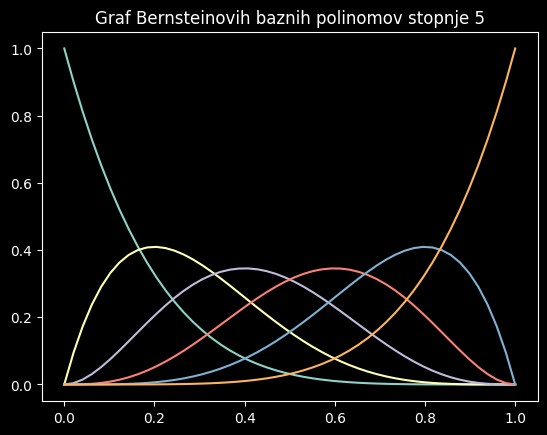

In [4]:
N = 5
x = np.linspace(0, 1)
plt.title("Graf Bernsteinovih baznih polinomov stopnje 5")
for i in range(N+1):
	b = np.zeros(N+1)
	b[i] = 1
	p = bernstein2power(b)
	plt.plot(x, np.polyval(p, x))

### Naloga 2. De Casteljaujev postopek

In [5]:
B = np.array([[0,0],[1,2],[3,3],[4,-1],[0,2]])
b = B[:,0]
decasteljau_basic(b, 1)

array([[ 0.,  1.,  3.,  4.,  0.],
       [ 1.,  3.,  4.,  0., nan],
       [ 3.,  4.,  0., nan, nan],
       [ 4.,  0., nan, nan, nan],
       [ 0., nan, nan, nan, nan]])

In [6]:
decasteljau(b, 1)

array([[[[ 0.,  1.,  3.,  4.,  0.],
         [ 1.,  3.,  4.,  0., nan],
         [ 3.,  4.,  0., nan, nan],
         [ 4.,  0., nan, nan, nan],
         [ 0., nan, nan, nan, nan]]]])

In [7]:
decasteljau(B, 0)

array([[[[ 0.,  0.,  0.,  0.,  0.],
         [ 1.,  1.,  1.,  1., nan],
         [ 3.,  3.,  3., nan, nan],
         [ 4.,  4., nan, nan, nan],
         [ 0., nan, nan, nan, nan]],

        [[ 0.,  0.,  0.,  0.,  0.],
         [ 2.,  2.,  2.,  2., nan],
         [ 3.,  3.,  3., nan, nan],
         [-1., -1., nan, nan, nan],
         [ 2., nan, nan, nan, nan]]]])

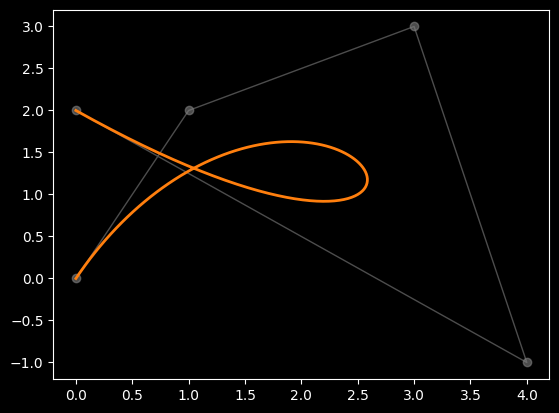

In [8]:
B = np.array([[0,0],[1,2],[3,3],[4,-1],[0,2]])
t = np.linspace(0,1,100)

plotbezier(B, t, "tab:orange")

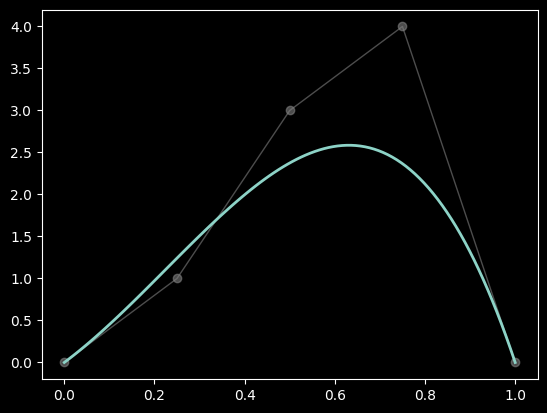

In [9]:
plotbezier(B[:,0], t)

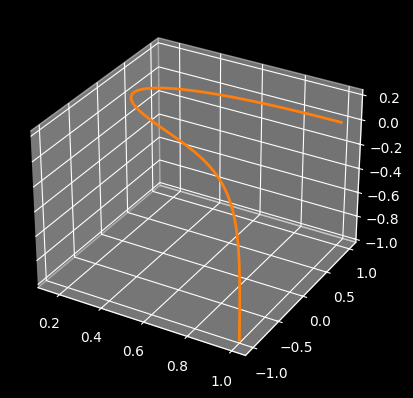

In [10]:
B = np.array([
	[1,1,0],
	[-1,1,0],
	[1,-1,0],
	[1,-1,1],
	[1,-1,-1]
])

t = np.linspace(0, 1, 100)

plotbezier(B, t, "tab:orange", controls=False)

### Naloga 3. Odvodi Bezierjeve krivulje

In [11]:
B = np.array([[-2/3,-4/5],[1/3,1/5],[0,0],[-1/3,1/5],[2/3,-4/5]])
t = np.linspace(0,1,9)

bezierder(B,1,t) # TODO: preveri ali je dovolj natančna

(array([[ 4.00000000e+00,  4.00000000e+00],
        [ 2.25000000e+00,  2.47500000e+00],
        [ 1.00000000e+00,  1.40000000e+00],
        [ 2.50000000e-01,  6.25000000e-01],
        [ 1.11022302e-16,  0.00000000e+00],
        [ 2.50000000e-01, -6.25000000e-01],
        [ 1.00000000e+00, -1.40000000e+00],
        [ 2.25000000e+00, -2.47500000e+00],
        [ 4.00000000e+00, -4.00000000e+00]]),
 array([[ 4.        ,  4.        ],
        [-1.33333333, -0.8       ],
        [-1.33333333,  0.8       ],
        [ 4.        , -4.        ]]))

In [12]:
t = np.arange(0.46,0.54,0.01)
d1b, _ = bezierder(B, 1, t)
R = np.hstack((t.reshape(-1,1), d1b))

with np.printoptions(precision=4, suppress=True):
	print(R)

[[ 0.46    0.0256  0.1928]
 [ 0.47    0.0144  0.1443]
 [ 0.48    0.0064  0.0961]
 [ 0.49    0.0016  0.048 ]
 [ 0.5     0.      0.    ]
 [ 0.51    0.0016 -0.048 ]
 [ 0.52    0.0064 -0.0961]
 [ 0.53    0.0144 -0.1443]
 [ 0.54    0.0256 -0.1928]]


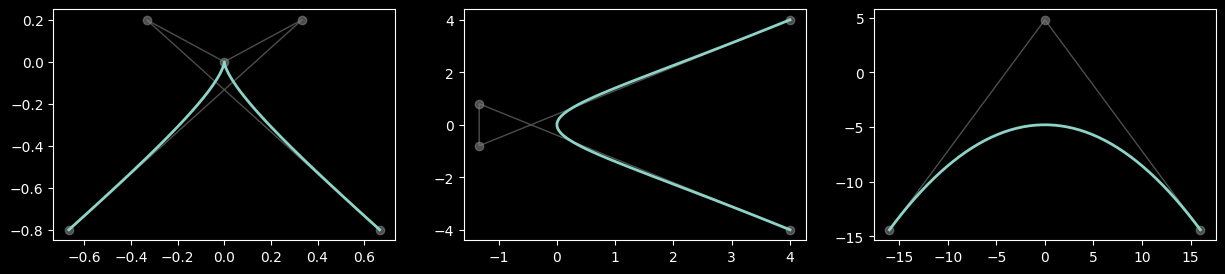

In [13]:
t = np.linspace(0, 1)
d1b, d1B = bezierder(B,1,t)
d2b, d2B = bezierder(B,2,t)

plt.figure(figsize=(15,3))
plt.subplot(1, 3, 1)
plotbezier(B, t)
plt.subplot(1, 3, 2)
plotbezier(d1B, t)
plt.subplot(1, 3, 3)
plotbezier(d2B, t)

### Naloga 4. Opis krožnice z Bezierjevimi krivuljami

[[ 0.80901699 -0.58778525]
 [ 1.23606798  0.        ]
 [ 0.80901699  0.58778525]]
[[ 0.80901699 -0.58778525]
 [ 1.00494541 -0.31811292]
 [ 1.00494541  0.31811292]
 [ 0.80901699  0.58778525]]
[[ 0.80901699 -0.58778525]
 [ 1.063661   -0.23729784]
 [ 1.063661    0.23729784]
 [ 0.80901699  0.58778525]]
e1 = 0.022542485937368628
e2 = 0.04403669255193421
e3 = 7.130701741275836e-05


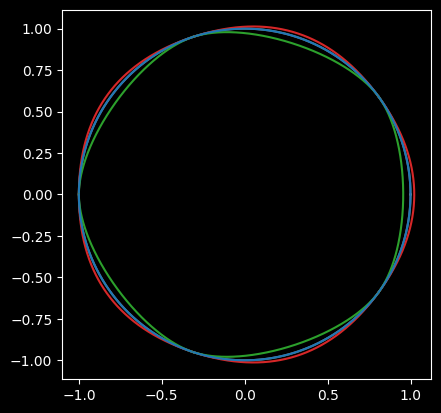

In [14]:
N = 5
fi = np.pi/N

B1 = bezierarc(fi, 1)
print(B1)
B2 = bezierarc(fi, 2)
print(B2)
B3 = bezierarc(fi, 3)
print(B3)

t = np.linspace(0, 1, 10001)
b1 = bezier(B1, t)
b2 = bezier(B2, t)
b3 = bezier(B3, t)

print(f"e1 = {np.max(np.abs(1 - np.linalg.norm(b1, axis=1)))}")
print(f"e2 = {np.max(np.abs(1 - np.linalg.norm(b2, axis=1)))}")
print(f"e3 = {np.max(np.abs(1 - np.linalg.norm(b3, axis=1)))}")

c = np.cos(2*fi)
s = np.sin(2*fi)
R = np.array([[c, -s],[s, c]])

plt.plot(np.cos(2*np.pi*t), np.sin(2*np.pi*t), color="gray")

for _ in range(N):
	b1 = (R @ b1.T).T
	b2 = (R @ b2.T).T
	b3 = (R @ b3.T).T
	plt.plot(b1[:,0], b1[:,1], color="tab:red")
	plt.plot(b2[:,0], b2[:,1], color="tab:green")
	plt.plot(b3[:,0], b3[:,1], color="tab:blue")
	
plt.gca().set_aspect('equal')

### Naloga 5. Subdivizija Bezierjeve krivulje

In [15]:
B = np.array([[0,0],[2,3],[4,2],[5,-1]])

beziersub(B, 0.5, 3)

[array([[0.        , 0.        ],
        [0.25      , 0.375     ],
        [0.5       , 0.6875    ],
        [0.74804688, 0.94140625]]),
 array([[0.74804688, 0.94140625],
        [0.99609375, 1.1953125 ],
        [1.2421875 , 1.390625  ],
        [1.484375  , 1.53125   ]]),
 array([[1.484375  , 1.53125   ],
        [1.7265625 , 1.671875  ],
        [1.96484375, 1.7578125 ],
        [2.19726562, 1.79296875]]),
 array([[2.19726562, 1.79296875],
        [2.4296875 , 1.828125  ],
        [2.65625   , 1.8125    ],
        [2.875     , 1.75      ]]),
 array([[2.875     , 1.75      ],
        [3.09375   , 1.6875    ],
        [3.3046875 , 1.578125  ],
        [3.50585938, 1.42578125]]),
 array([[3.50585938, 1.42578125],
        [3.70703125, 1.2734375 ],
        [3.8984375 , 1.078125  ],
        [4.078125  , 0.84375   ]]),
 array([[4.078125  , 0.84375   ],
        [4.2578125 , 0.609375  ],
        [4.42578125, 0.3359375 ],
        [4.58007812, 0.02734375]]),
 array([[ 4.58007812,  0.02734375]

### Naloga 6. Višanje stopnje Bezierjeve krivulje

In [16]:
B = np.array([[0,0],[2,6],[3,0],[5,4],[7,1],[5,5],[10,6]])
bezierelv(B, 2)

array([[ 0.        ,  0.        ],
       [ 1.5       ,  4.5       ],
       [ 2.46428571,  2.57142857],
       [ 3.60714286,  2.07142857],
       [ 5.        ,  2.5       ],
       [ 6.07142857,  2.5       ],
       [ 6.25      ,  2.89285714],
       [ 6.25      ,  5.25      ],
       [10.        ,  6.        ]])

### Naloga 7. Parametrizacija sestavljene krivulje

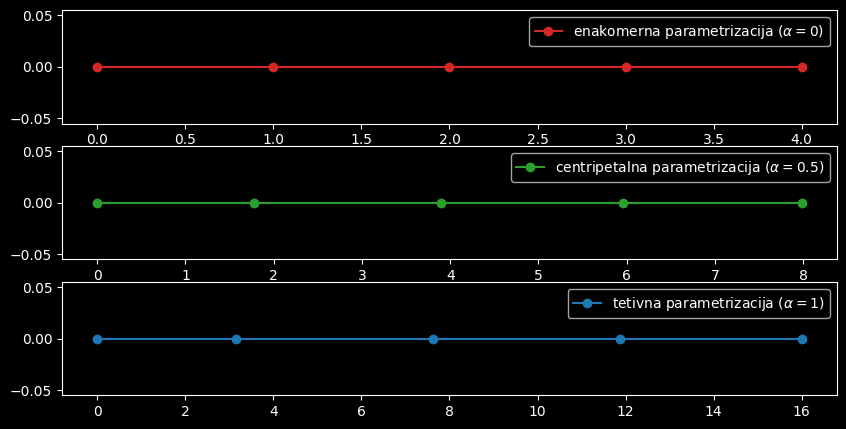

In [17]:
P = np.array([[-5,0],[-2,-1],[0,3],[3,0],[7,-1]])

ue = alphaparam(P, 0)
uc = alphaparam(P, 0.5)
ut = alphaparam(P, 1)
z = np.zeros(5)
plt.figure(figsize=(10, 5))
plt.subplot(3, 1, 1)
plt.plot(ue, z, '-o', label='enakomerna parametrizacija ($\\alpha = 0$)', color='tab:red')
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(uc, z, '-o', label='centripetalna parametrizacija ($\\alpha = 0.5$)', color='tab:green')
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(ut, z, '-o', label='tetivna parametrizacija ($\\alpha = 1$)', color='tab:blue')
plt.legend()

### Naloga 8

In [18]:
D = np.array([[-5,0],[-4,1],[-2,-1],[0,3],[3,0],[5,2],[7,-1]])
P = D[[0, 2, 3, 4, 6]]

ue = alphaparam(P, 0)
Be = beziercubspline(ue, D)

In [19]:
Be 

[array([[-5.        ,  0.        ],
        [-4.        ,  1.        ],
        [-3.        ,  0.        ],
        [-2.16666667,  0.16666667]]),
 array([[-2.16666667,  0.16666667],
        [-1.33333333,  0.33333333],
        [-0.66666667,  1.66666667],
        [ 0.16666667,  1.83333333]]),
 array([[0.16666667, 1.83333333],
        [1.        , 2.        ],
        [2.        , 1.        ],
        [3.        , 1.        ]]),
 array([[ 3.,  1.],
        [ 4.,  1.],
        [ 5.,  2.],
        [ 7., -1.]])]

### Naloga 9. Racionalne Bezierjeve krivulje in Farinove točke

In [20]:
B = matlab("0 0; 2 3; 5 0; 3 -1; 2 -1")
w = matlab("0.5; 0.7; 0.8; 1; 0.6")

t = np.linspace(0, 1, 10)

P = rbezier(B, w, t)
print(P)

[[ 0.          0.        ]
 [ 1.17768357  1.1169205 ]
 [ 2.15024327  1.2870545 ]
 [ 2.85223368  1.00687285]
 [ 3.26626004  0.54606107]
 [ 3.4107915   0.05884565]
 [ 3.32436472 -0.37070254]
 [ 3.04918529 -0.70209066]
 [ 2.61389251 -0.91784023]
 [ 2.         -1.        ]]


In [21]:
w1 = w.copy()
w1[1] = 0.7

P1 = rbezier(B, w1, t)
print(P1)

[[ 0.          0.        ]
 [ 1.17768357  1.1169205 ]
 [ 2.15024327  1.2870545 ]
 [ 2.85223368  1.00687285]
 [ 3.26626004  0.54606107]
 [ 3.4107915   0.05884565]
 [ 3.32436472 -0.37070254]
 [ 3.04918529 -0.70209066]
 [ 2.61389251 -0.91784023]
 [ 2.         -1.        ]]


In [22]:
w2 = w.copy()
w2[1] = 2
rbezier(B, w2, t)

array([[ 0.        ,  0.        ],
       [ 1.51534594,  1.89015701],
       [ 2.08208167,  2.0641748 ],
       [ 2.49699399,  1.83767535],
       [ 2.83680098,  1.37832796],
       [ 3.07460977,  0.75970213],
       [ 3.1461837 ,  0.08279431],
       [ 2.99444584, -0.50894041],
       [ 2.60865643, -0.88442376],
       [ 2.        , -1.        ]])

In [23]:
w3 = w.copy()
w3[1] = 0.2
rbezier(B, w2, t)

array([[ 0.        ,  0.        ],
       [ 1.51534594,  1.89015701],
       [ 2.08208167,  2.0641748 ],
       [ 2.49699399,  1.83767535],
       [ 2.83680098,  1.37832796],
       [ 3.07460977,  0.75970213],
       [ 3.1461837 ,  0.08279431],
       [ 2.99444584, -0.50894041],
       [ 2.60865643, -0.88442376],
       [ 2.        , -1.        ]])

Text(0.5, 1.0, 'w[1] = 0.2')

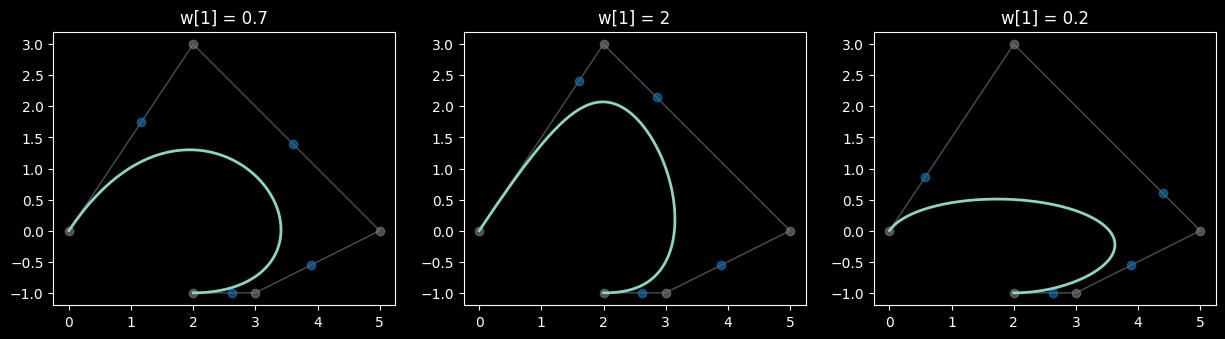

In [24]:
t = np.linspace(0, 1, 100)
plt.figure(figsize=(15,4))
plt.subplot(1, 3, 1)
plotrbezier(B, w1, t)
plt.title("w[1] = 0.7")
plt.subplot(1, 3, 2)
plotrbezier(B, w2, t)
plt.title("w[1] = 2")
plt.subplot(1, 3, 3)
plotrbezier(B, w3, t)
plt.title("w[1] = 0.2")

### Naloga 10. Višanje stopnje Bezierjeve krivulje

In [25]:
B = matlab("1 0; 1 4; -3 2; -3 -2; 1 -4; 1 0")
w = matlab("1; 1/5; 1/5; 1/5; 1/5; 1")

Be, we = rbezierelv(B, w, 1)
Be, we

(array([[ 1.        ,  0.        ],
        [ 1.        ,  2.        ],
        [-1.66666667,  2.66666667],
        [-3.        ,  0.        ],
        [-1.66666667, -2.66666667],
        [ 1.        , -2.        ],
        [ 1.        ,  0.        ]]),
 array([[1.        ],
        [0.33333333],
        [0.2       ],
        [0.2       ],
        [0.2       ],
        [0.33333333],
        [1.        ]]))

In [26]:
rbezierelv(Be, we)

(array([[ 1.        ,  0.        ],
        [ 1.        ,  1.33333333],
        [-0.6       ,  2.4       ],
        [-2.42857143,  1.14285714],
        [-2.42857143, -1.14285714],
        [-0.6       , -2.4       ],
        [ 1.        , -1.33333333],
        [ 1.        ,  0.        ]]),
 array([[1.        ],
        [0.42857143],
        [0.23809524],
        [0.2       ],
        [0.2       ],
        [0.23809524],
        [0.42857143],
        [1.        ]]))

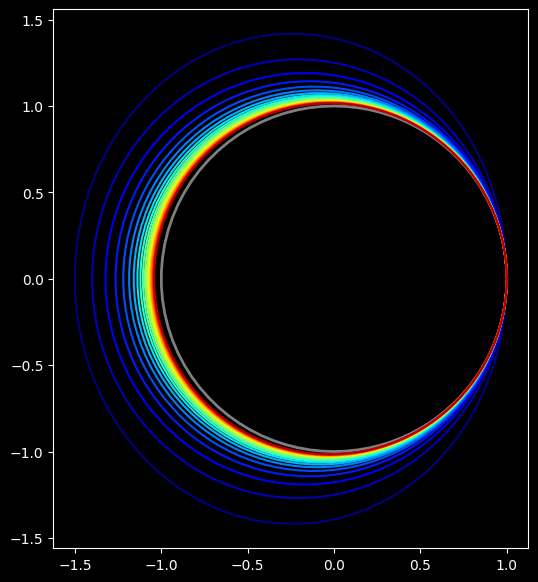

In [27]:
t = np.linspace(0, 1, 100)
b = rbezier(B, w, t)
N = 20

plt.figure(figsize=(7,7))
plt.plot(b[:,0], b[:,1], color="tab:gray", linewidth=2)

Be, we = B.copy(), w.copy()
cmap = plt.get_cmap("jet")
for i in range(N):
	Be, we = rbezierelv(Be.copy(), we.copy())
	b = bezier(Be, t)
	plt.plot(b[:,0], b[:,1], color=cmap(i/N))

plt.gca().set_aspect('equal')

### Naloga 11. Bezierjeve ploskve iz tenzorskega produkta.

In [126]:
Bx = matlab("0 3 5 6; 1 4 5 7; 0 3 5 6")
By = matlab("-1 -2 -1 -2; 1 2 1 2; 5 5 6 5")
Bz = matlab("-3 -2 0 -5; 3 6 3 2; -1 4 -2 8")
B = np.stack((Bx, By, Bz), axis=2)

U = V = np.linspace(0, 1, 7)

bx, by, bz = bezier2(Bx, By, Bz, U, V)

with np.printoptions(precision=4, suppress=True):
	print("bx: \n", bx)
	print("by: \n", by)
	print("bz: \n", bz)

bx: 
 [[0.     1.4167 2.6667 3.75   4.6667 5.4167 6.    ]
 [0.2778 1.6752 2.8827 3.9236 4.821  5.598  6.2778]
 [0.4444 1.8302 3.0123 4.0278 4.9136 5.7068 6.4444]
 [0.5    1.8819 3.0556 4.0625 4.9444 5.7431 6.5   ]
 [0.4444 1.8302 3.0123 4.0278 4.9136 5.7068 6.4444]
 [0.2778 1.6752 2.8827 3.9236 4.821  5.598  6.2778]
 [0.     1.4167 2.6667 3.75   4.6667 5.4167 6.    ]]
by: 
 [[-1.     -1.3519 -1.4815 -1.5    -1.5185 -1.6481 -2.    ]
 [-0.2778 -0.4225 -0.4722 -0.4757 -0.4815 -0.5382 -0.6944]
 [ 0.5556  0.5633  0.5802  0.5972  0.6049  0.5941  0.5556]
 [ 1.5     1.6053  1.6759  1.7188  1.7407  1.7488  1.75  ]
 [ 2.5556  2.7037  2.8148  2.8889  2.9259  2.9259  2.8889]
 [ 3.7222  3.8584  3.9969  4.1076  4.1605  4.1254  3.9722]
 [ 5.      5.0694  5.2222  5.375   5.4444  5.3472  5.    ]]
bz: 
 [[-3.     -2.4537 -1.963  -1.75   -2.037  -3.0463 -5.    ]
 [-1.2778 -0.5629 -0.1327 -0.059  -0.4136 -1.2681 -2.6944]
 [-0.1111  0.7824  1.1852  1.1806  0.8519  0.2824 -0.4444]
 [ 0.5     1.5822  1.9907 

In [53]:
%matplotlib inline

<Figure size 700x700 with 0 Axes>

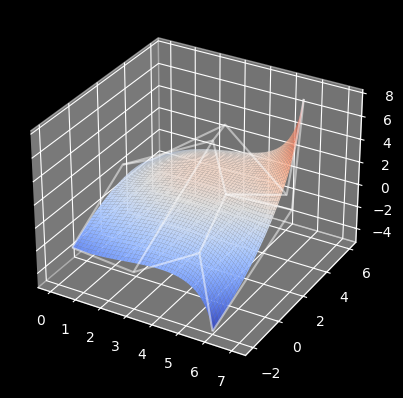

In [127]:
plt.figure(figsize=(7,7))
U = V = np.linspace(0, 1, 100)
plotbezier2(Bx, By, Bz, U, V)

### Naloga 12. Coonsove ploskve

In [128]:
Bx = np.zeros((9,7))
By = np.zeros((9,7))
Bz = np.zeros((9,7))

phi = np.linspace(0, np.pi, 7)
psi = np.linspace(0, np.pi, 9)


Bx[0,:] = 1+np.sin(phi)
By[0,:] = -np.cos(phi)

Bx[-1,:] = -1-np.sin(phi)
By[-1,:] = -np.cos(phi)

Bx[:,0] = np.cos(psi)
By[:,0] = -1

Bz[:, 0] = np.sin(psi)
Bx[:, -1] = np.cos(psi)

By[:, -1] = 1
Bz[:, -1] = np.sin(psi)


Bx, By, Bz = coons(Bx, By, Bz)


with np.printoptions(precision=4, suppress=True):
	print("Bx: \n", Bx)
	print("By: \n", By)
	print("Bz: \n", Bz)

Bx: 
 [[ 1.      1.5     1.866   2.      1.866   1.5     1.    ]
 [ 0.9239  1.2989  1.5734  1.6739  1.5734  1.2989  0.9239]
 [ 0.7071  0.9571  1.1401  1.2071  1.1401  0.9571  0.7071]
 [ 0.3827  0.5077  0.5992  0.6327  0.5992  0.5077  0.3827]
 [ 0.      0.      0.      0.      0.      0.      0.    ]
 [-0.3827 -0.5077 -0.5992 -0.6327 -0.5992 -0.5077 -0.3827]
 [-0.7071 -0.9571 -1.1401 -1.2071 -1.1401 -0.9571 -0.7071]
 [-0.9239 -1.2989 -1.5734 -1.6739 -1.5734 -1.2989 -0.9239]
 [-1.     -1.5    -1.866  -2.     -1.866  -1.5    -1.    ]]
By: 
 [[-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.866  1.   ]
 [-1.    -0.866 -0.5   -0.     0.5    0.

<Figure size 1000x1000 with 0 Axes>

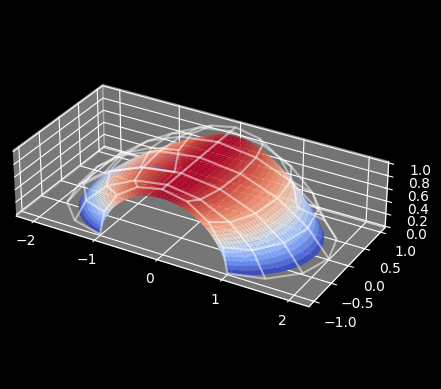

In [132]:
plt.figure(figsize=(10,10))
u = v = np.linspace(0,1,50)
plotbezier2(Bx, By, Bz, u, v)

### Naloga 13. Aprokicmacija z Bezierjevimi krivuljami po metodi najmanjših kvadratov

In [182]:
x, y, z = peaks(50)

with np.printoptions(precision=4, suppress=True):
	print(z)

[[ 0.0001  0.0001  0.0002 ... -0.0001 -0.     -0.    ]
 [ 0.0001  0.0002  0.0003 ... -0.0001 -0.     -0.    ]
 [ 0.0002  0.0003  0.0005 ... -0.0001 -0.0001 -0.    ]
 ...
 [ 0.0001  0.0002  0.0003 ...  0.0005  0.0002  0.0001]
 [ 0.0001  0.0001  0.0002 ...  0.0003  0.0001  0.0001]
 [ 0.      0.0001  0.0001 ...  0.0002  0.0001  0.    ]]


In [173]:
P = np.hstack(((x.T.flatten()[:, None]+3)/6, (y.T.flatten()[:, None]+3)/6, z.T.flatten()[:, None]))
with np.printoptions(precision=4, suppress=True):
	print(P)

[[0.     0.     0.0001]
 [0.     0.0204 0.0001]
 [0.     0.0408 0.0002]
 ...
 [1.     0.9592 0.0001]
 [1.     0.9796 0.0001]
 [1.     1.     0.    ]]


In [178]:
P[:, 0].shape

(2500,)

In [204]:
m = 6; n = 5
Bx, By = np.meshgrid(np.linspace(-3,3,m+1), np.linspace(-3,3,n+1))

Bz = lsqbezier2(m, n, P)
with np.printoptions(precision=4, suppress=True):
	print(Bz)

[[  -0.064     1.2497   -6.9336   11.3035   -3.8045    1.2077   -0.1178]
 [   0.4847  -10.6778   61.5171 -120.9325   50.8883  -14.8798    1.3845]
 [   4.3289  -33.7952   60.9573   15.4253  -34.4044   23.1744   -3.2218]
 [  -3.4583   32.3424  -94.5316    3.9893   56.2546  -20.2017    2.2863]
 [   0.1022    2.7193  -23.6613  127.2018  -86.8229   21.8897   -1.8355]
 [  -0.0321    0.0113    1.0979  -12.37      9.3843   -2.3252    0.1926]]


In [206]:
# Izračun vrenosti v točkah mreže
u = v = np.linspace(0,1,7)
bx,by,bz = bezier2(Bx, By, Bz, u, v)

with np.printoptions(precision=4, suppress=True):
	print(bz)

[[-0.064  -0.3366  0.2283  1.2431  0.9859  0.2322 -0.1178]
 [ 0.7541  0.638  -0.4826 -3.5943 -2.4867  0.0998  0.0588]
 [ 1.0111 -0.0803  0.1081 -1.5    -0.6808  0.9262 -0.3188]
 [ 0.3608 -1.1137 -0.2862  1.4325  2.0699  1.2941 -0.3605]
 [-0.3769 -1.1661  0.4246  4.0176  3.3267  0.6862 -0.3001]
 [-0.387  -0.1604  2.5365  5.0499  2.3442 -0.2834 -0.3919]
 [-0.0321 -0.3745 -1.619  -1.6233 -0.1305  0.3617  0.1926]]


In [224]:
u = v = np.linspace(0,1,50)
bx,by,bz = bezier2(Bx, By, Bz, u, v)

# Maksimalna absolutna napaka v točkah mreže
_, _, bz = bezier2(Bx, By, Bz, u, v)

np.max(np.abs(bz.T.flatten() - P[:,2]))

4.0880331935645655

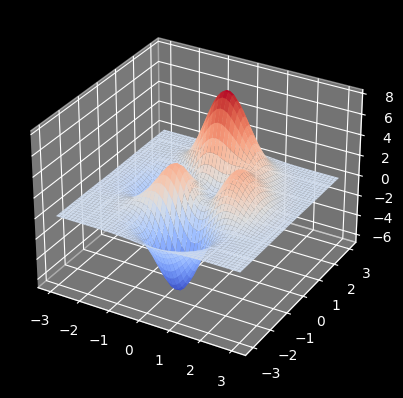

In [194]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(x, y, z, alpha=1, cmap="coolwarm")

In [225]:
%matplotlib inline

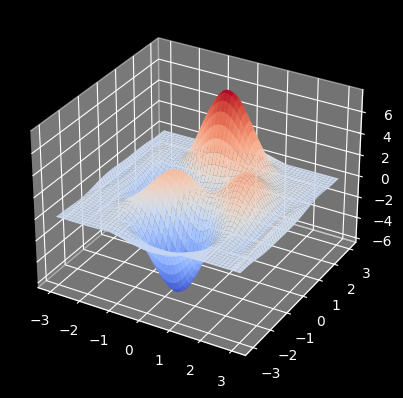

In [227]:
m = 9; n = 10
Bx, By = np.meshgrid(np.linspace(-3,3,m+1), np.linspace(-3,3,n+1))

Bz = lsqbezier2(m, n, P)

u = v = np.linspace(0,1,50)
bx,by,bz = bezier2(Bx, By, Bz, u, v)
ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(bx, by, bz, alpha=1, cmap="coolwarm")

### Naloga 14. Aproksimacija s sestavljenimi Bezierjevimi krivuljami

In [238]:
x, y, z = peaks(50)
P = np.hstack(((x.T.flatten()[:, None]+3)/6, (y.T.flatten()[:, None]+3)/6, z.T.flatten()[:, None]))

In [296]:
M = 5
N = 4
m = 3
n = 4

I = np.arange(M+1)
J = np.arange(N+1)

U = I / M
V = J / N

B = dict()

for i in range(1, M+1):
	for j in range(1, N+1):
		print(f"{(i,j)}, pravokotnik {(U[i-1], U[i])}x{(V[j-1], V[j])}")

		u = P[:, 0, None]
		v = P[:, 1, None]
		f = P[:, 2, None]

		mask = (U[i-1] <= u) & (u <= U[i]) & (V[j-1] <= v) & (v <= V[j])
		P_ = np.hstack(((u-U[i-1])/(U[i] - U[i-1]), (v-V[j-1])/(V[j]-V[j-1]), f))

		Bz = lsqbezier2(m, n, P_[mask.flatten()])
		B[(i, j)] = Bz

# fix edges
for II in range(1, M+1):
	for JJ in range(1, N+1):
		for ii in range(m+1):
			if JJ > 1:
				val = 1/2 * B[(II,JJ-1)][n-1, ii] + 1/2 * B[(II,JJ)][1, ii]
				B[(II, JJ)][0,ii] = B[(II,JJ-1)][n,ii] = val
		for jj in range(n+1):
			if II > 1:
				val = 1/2 * B[(II-1,JJ)][jj,m-1] + 1/2 * B[(II,JJ)][jj,1]
				B[(II, JJ)][jj,0] = B[(II-1,JJ)][jj,m] = val

		if II > 1 and JJ > 1:
			val = 1/4 * B[(II, JJ)][1,1] + 1/4 * B[(II-1,JJ)][1,m-1]  + 1/4 * B[(II-1,JJ-1)][n-1, m-1] + 1/4 * B[(II,JJ-1)][n-1,1]
			B[(II, JJ)][0,0] = val
			B[(II-1, JJ)][0,m] = val
			B[(II-1, JJ-1)][n,m] = val
			B[(II, JJ-1)][n,0] = val
		


(1, 1), pravokotnik (0.0, 0.2)x(0.0, 0.25)
(1, 2), pravokotnik (0.0, 0.2)x(0.25, 0.5)
(1, 3), pravokotnik (0.0, 0.2)x(0.5, 0.75)
(1, 4), pravokotnik (0.0, 0.2)x(0.75, 1.0)
(2, 1), pravokotnik (0.2, 0.4)x(0.0, 0.25)
(2, 2), pravokotnik (0.2, 0.4)x(0.25, 0.5)
(2, 3), pravokotnik (0.2, 0.4)x(0.5, 0.75)
(2, 4), pravokotnik (0.2, 0.4)x(0.75, 1.0)
(3, 1), pravokotnik (0.4, 0.6)x(0.0, 0.25)
(3, 2), pravokotnik (0.4, 0.6)x(0.25, 0.5)
(3, 3), pravokotnik (0.4, 0.6)x(0.5, 0.75)
(3, 4), pravokotnik (0.4, 0.6)x(0.75, 1.0)
(4, 1), pravokotnik (0.6, 0.8)x(0.0, 0.25)
(4, 2), pravokotnik (0.6, 0.8)x(0.25, 0.5)
(4, 3), pravokotnik (0.6, 0.8)x(0.5, 0.75)
(4, 4), pravokotnik (0.6, 0.8)x(0.75, 1.0)
(5, 1), pravokotnik (0.8, 1.0)x(0.0, 0.25)
(5, 2), pravokotnik (0.8, 1.0)x(0.25, 0.5)
(5, 3), pravokotnik (0.8, 1.0)x(0.5, 0.75)
(5, 4), pravokotnik (0.8, 1.0)x(0.75, 1.0)


[[ 0.0001 -0.      0.001   0.0041]
 [ 0.0003  0.0006  0.0031  0.0235]
 [ 0.     -0.0017  0.0034 -0.0112]
 [ 0.0032 -0.0034  0.0446  0.1163]
 [-0.0008  0.0087 -0.0282  0.1214]]


In [307]:
M = 5
N = 4
m = 3
n = 4
B = lsqbezier2spline(M, N, m, N, P)

with np.printoptions(precision=4, suppress=True):
	print(B[(1, 3)])

[[ -0.1179  -0.2345  -0.3141  -0.2064]
 [ -0.3146  -0.6731  -0.9364  -0.6223]
 [ -0.6712  -1.2194  -1.5699  -1.0099]
 [ -4.1526  -7.9253 -10.0177  -6.607 ]
 [ -1.9805  -5.0556  -9.002   -5.7833]]


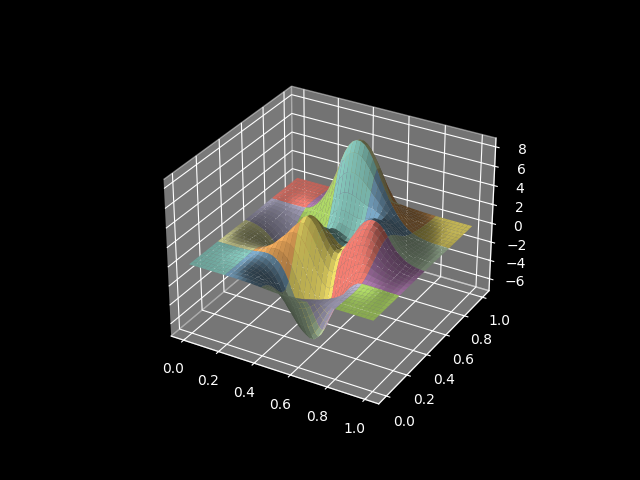

In [309]:
ax = plt.figure().add_subplot(projection='3d')
for i in range(1, M+1):
	for j in range(1, N+1):
		Bz = B[(j, i)]
		Bx, By = np.meshgrid(np.linspace(U[i-1], U[i], m+1), np.linspace(V[j-1], V[j], n+1))
		u = v = np.linspace(0,1,10)
		bx, by, bz = bezier2(Bx, By, Bz, u, v)
		ax.plot_surface(bx, by, bz)


### Naloga 15. Polinomi dveh spremenljivk

In [361]:
from helpers import *

In [378]:
T = matlab("0 0; 5 1; 3 3") # trikotnik
pointbary(np.array([0,0]), T)

array([1., 0., 0.])

In [379]:
with np.printoptions(precision=4, suppress=True):
	p1 = pointbary(np.array([0,0]), T)
	print(f"{p1 = }")
	p2 = pointbary(np.array([1,1]), T)
	print(f"{p2 = }")
	p3 = pointbary(np.array([4,2]), T)
	print(f"{p3 = }")
	x = vectorbary(np.array([1,0]), T)
	print(f"{x = }")
	y = vectorbary(np.array([0,1]), T)
	print(f"{y = }")

p1 = array([1., 0., 0.])
p2 = array([ 0.6667, -0.    ,  0.3333])
p3 = array([0. , 0.5, 0.5])
x = array([-0.1667,  0.25  , -0.0833])
y = array([-0.1667, -0.25  ,  0.4167])


In [380]:
B = np.array([[2,1,-1,0],[5,3,-4,np.nan],[0,0,np.nan,np.nan],[1,np.nan,np.nan,np.nan]])

In [381]:
# vrednosti p v točkah (0,0), (1,1), (4,2)
np.array([decasteljau3(B, p1), decasteljau3(B, p2), decasteljau3(B, p3)])

array([ 2.        ,  2.85185185, -1.375     ])

In [382]:
# vrednosti Dxp v točkah (0,0), (1,1), (4,2)
3*np.array([blossom3(B, np.vstack((x, p1, p1))), blossom3(B, np.vstack((x, p2, p2))), blossom3(B, np.vstack((x, p3, p3)))])

array([-1.5       , -0.80555556, -1.9375    ])

In [365]:
# vrednosti Dyp v točkah (0,0), (1,1), (4,2)
3*np.array([blossom3(B, np.vstack((y, p1, p1))), blossom3(B, np.vstack((y, p2, p2))), blossom3(B, np.vstack((y, p3, p3)))])

array([ 4.5       ,  0.02777778, -0.0625    ])

In [366]:
# vrednosti Dxxp v točkah (0,0), (1,1), (4,2)
6*np.array([blossom3(B, np.vstack((x, x, p1))), blossom3(B, np.vstack((x, x, p2))), blossom3(B, np.vstack((x, x, p3)))])

array([-0.45833333, -1.01388889,  0.02083333])

In [367]:
# vrednosti Dxyp v točkah (0,0), (1,1), (4,2)
6*np.array([blossom3(B, np.vstack((x, y, p1))), blossom3(B, np.vstack((x, y, p2))), blossom3(B, np.vstack((x, y, p3)))])

array([ 1.29166667,  1.56944444, -0.85416667])

In [368]:
# vrednosti Dyyp v točkah (0,0), (1,1), (4,2)
6*np.array([blossom3(B, np.vstack((y, y, p1))), blossom3(B, np.vstack((y, y, p2))), blossom3(B, np.vstack((y, y, p3)))])

array([-7.45833333, -4.34722222,  2.02083333])

### Naloga 16. Trikotne Bezierjeve ploskve

In [369]:
from helpers import *

In [373]:
trimeshgrid(2)

(array([[1., 2., 4.],
        [2., 4., 5.],
        [2., 3., 5.],
        [4., 5., 6.]]),
 array([[1. , 0. , 0. ],
        [0.5, 0.5, 0. ],
        [0. , 1. , 0. ],
        [0.5, 0. , 0.5],
        [0. , 0.5, 0.5],
        [0. , 0. , 1. ]]))

In [393]:
Bx = np.array([[0,2,6,8],[1,3,7,np.nan],[2,5,np.nan,np.nan],[4,np.nan,np.nan,np.nan]])
By = np.array([[0,1,0,-1],[2,2,3,np.nan],[4,3,np.nan,np.nan],[5,np.nan,np.nan,np.nan]])
Bz = np.array([[-2,1,-2,0],[4,-2,3,np.nan],[0,5,np.nan,np.nan],[3,np.nan,np.nan,np.nan]])


_, U = trimeshgrid(3)
b = bezier3(Bx, By, Bz, U)

with np.printoptions(precision=4, suppress=True):
	print(b)

[[ 0.      0.     -2.    ]
 [ 2.5185  0.4074 -0.5926]
 [ 5.4815 -0.0741 -0.7407]
 [ 8.     -1.      0.    ]
 [ 1.037   1.963   1.2963]
 [ 3.6667  2.037   0.8148]
 [ 6.7407  1.8889  2.5556]
 [ 2.2963  3.7037  1.7037]
 [ 5.2593  3.4444  3.7778]
 [ 4.      5.      3.    ]]


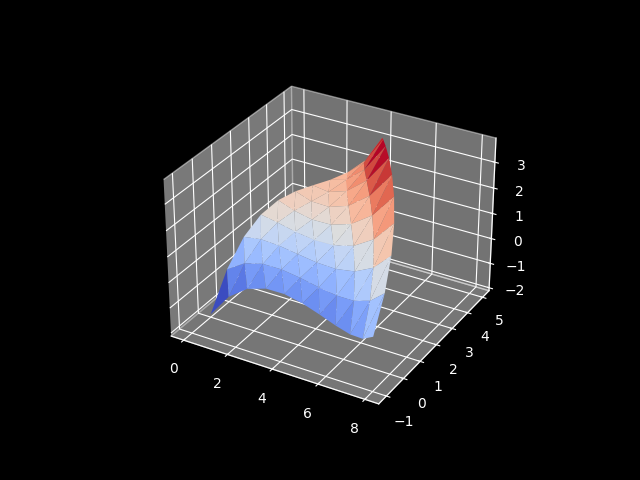

In [408]:
TRI, U = trimeshgrid(10)
b = bezier3(Bx, By, Bz, U)

ax = plt.figure().add_subplot(projection='3d')
ax.plot_trisurf(b[:,0], b[:,1], b[:,2], cmap="coolwarm", triangles=TRI)

### Naloga 17. Argyrisova interpolacijska shema

In [409]:
def f(V):
    x = V[0]
    y = V[1]
    return 3 * (1 - x)**2 * np.exp(-x**2 - (y + 1)**2) \
           - 10 * (x / 5 - x**3 - y**5) * np.exp(-x**2 - y**2) \
           - (1 / 3) * np.exp(-(x + 1)**2 - y**2)

def dxf(V):
    x = V[0]
    y = V[1]
    return (np.exp(-(x + 1)**2 - y**2) * (2 * x + 2)) / 3 \
           + 3 * np.exp(-(y + 1)**2 - x**2) * (2 * x - 2) \
           + np.exp(-x**2 - y**2) * (30 * x**2 - 2) \
           - 6 * x * np.exp(-(y + 1)**2 - x**2) * (x - 1)**2 \
           - 2 * x * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5)

def dyf(V):
    x = V[0]
    y = V[1]
    return (2 * y * np.exp(-(x + 1)**2 - y**2)) / 3 \
           + 50 * y**4 * np.exp(-x**2 - y**2) \
           - 3 * np.exp(-(y + 1)**2 - x**2) * (2 * y + 2) * (x - 1)**2 \
           - 2 * y * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5)

def Df(V):
    return np.array([dxf(V), dyf(V)])

def dxxf(V):
    x = V[0]
    y = V[1]
    return (2 * np.exp(-(x + 1)**2 - y**2)) / 3 \
           + 6 * np.exp(-(y + 1)**2 - x**2) \
           + 60 * x * np.exp(-x**2 - y**2) \
           - 6 * np.exp(-(y + 1)**2 - x**2) * (x - 1)**2 \
           - 2 * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5) \
           - (np.exp(-(x + 1)**2 - y**2) * (2 * x + 2)**2) / 3 \
           + 12 * x**2 * np.exp(-(y + 1)**2 - x**2) * (x - 1)**2 \
           + 4 * x**2 * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5) \
           - 12 * x * np.exp(-(y + 1)**2 - x**2) * (2 * x - 2) \
           - 4 * x * np.exp(-x**2 - y**2) * (30 * x**2 - 2)

def dxyf(V):
    x = V[0]
    y = V[1]
    return 4 * x * y * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5) \
           - (2 * y * np.exp(-(x + 1)**2 - y**2) * (2 * x + 2)) / 3 \
           - 2 * y * np.exp(-x**2 - y**2) * (30 * x**2 - 2) \
           - 100 * x * y**4 * np.exp(-x**2 - y**2) \
           - 3 * np.exp(-(y + 1)**2 - x**2) * (2 * x - 2) * (2 * y + 2) \
           + 6 * x * np.exp(-(y + 1)**2 - x**2) * (2 * y + 2) * (x - 1)**2

def dyyf(V):
    x = V[0]
    y = V[1]
    return (2 * np.exp(-(x + 1)**2 - y**2)) / 3 \
           - 6 * np.exp(-(y + 1)**2 - x**2) * (x - 1)**2 \
           - 2 * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5) \
           + 200 * y**3 * np.exp(-x**2 - y**2) \
           - 200 * y**5 * np.exp(-x**2 - y**2) \
           - (4 * y**2 * np.exp(-(x + 1)**2 - y**2)) / 3 \
           + 4 * y**2 * np.exp(-x**2 - y**2) * (10 * x**3 - 2 * x + 10 * y**5) \
           + 3 * np.exp(-(y + 1)**2 - x**2) * (2 * y + 2)**2 * (x - 1)**2

def Hf(V):
    return np.array([[dxxf(V), dxyf(V)], [dxyf(V), dyyf(V)]])

In [419]:
T = np.array([[-1.7, -1], [-0.5, -1], [-0.5, 0]])

Bz = argyris(T, f, Df, Hf)

with np.printoptions(precision=4, suppress=True):
	print(Bz)

[[ 0.0009  0.2372  0.807   2.4482  2.949   2.2247]
 [-0.0441  0.4645  2.1441  3.8935  3.8769     nan]
 [-0.121   1.6988  4.085   4.7002     nan     nan]
 [ 0.223   2.454   3.2656     nan     nan     nan]
 [ 1.3643  2.2532     nan     nan     nan     nan]
 [ 1.4796     nan     nan     nan     nan     nan]]


In [421]:
Bx = np.full((6,6), np.nan)
By = np.full((6,6), np.nan)
for i in range(6):
	for j in range(6-i):
		D = (5-i-j)/5 * T[0] + j/5 * T[1] + i/5 * T[2]
		Bx[i,j] = D[0]
		By[i,j] = D[1]

_, U3 = trimeshgrid(3)
with np.printoptions(precision=4, suppress=True):
	print(bezier3(Bx, By, Bz, U3))

[[-1.7    -1.      0.0009]
 [-1.3    -1.      0.8774]
 [-0.9    -1.      2.2124]
 [-0.5    -1.      2.2247]
 [-1.3    -0.6667  0.0447]
 [-0.9    -0.6667  2.2395]
 [-0.5    -0.6667  3.7531]
 [-0.9    -0.3333  0.6957]
 [-0.5    -0.3333  2.9541]
 [-0.5     0.      1.4796]]


### Naloga 18. Argyrisov zlepek

In [422]:
X = [-3.0, -3.0, -3.0, -3.0, -1.7, -1.6, -1.5, -1.1, -0.9,
-0.7, -0.5, -0.5, -0.5, -0.4, 0.0, 0.5, 0.5, 0.6, 0.7,
1.0, 1.2, 1.2, 1.6, 2.0, 2.0, 3.0, 3.0, 3.0, 3.0, 3.0]

Y = [-3.0, -2.0, 1.0, 3.0, -1.0, 0.5, 1.7, -3.0, -2.0, 1.0,
-1.0, 0.0, 3.0, 1.6, -2.0, -1.0, 0.5, 1.2, -0.4, 2.2,
-3.0, -1.6, 3.0, -1.0, 0.6, -3.0, -1.8, -0.4, 1.7, 3.0]


In [443]:
connectivity = np.array([
	[ 7,    14,   13],
    [ 7,     6,   10],
    [ 9,     2,    8],
    [20,    14,   18],
    [12,     6,    5],
    [27,    24,   22],
    [18,    14,   10],
    [ 5,     6,    3],
    [ 8,     2,    1],
    [22,    24,   19],
    [21,    15,    8],
    [12,    17,   10],
    [15,     9,    8],
    [12,    10,    6],
    [ 9,     5,    2],
    [22,    15,   21],
    [ 2,     5,    3],
    [17,    18,   10],
    [14,     7,   10],
    [ 3,     7,    4],
    [ 3,     6,    7],
    [ 4,     7,   13],
    [ 9,    11,    5],
    [19,    24,   25],
    [ 5,    11,   12],
    [ 9,    15,   11],
    [11,    19,   12],
    [18,    25,   20],
    [25,    29,   20],
    [20,    13,   14],
    [17,    25,   18],
    [23,    13,   20],
    [23,    20,   29],
    [30,    23,   29],
    [19,    25,   17],
    [24,    28,   25],
    [29,    25,   28],
    [12,    19,   17],
    [11,    15,   16],
    [19,    16,   22],
    [19,    11,   16],
    [15,    22,   16],
    [21,    27,   22],
    [28,    24,   27],
    [27,    21,   26]
])

connectivity -= 1

In [454]:
from helpers import *

In [444]:
from scipy.spatial import Delaunay

In [445]:
tri = Delaunay(np.column_stack((X, Y)))
tri

In [455]:
S = argyrisspline(connectivity, np.column_stack((X, Y)), f, Df, Hf)

In [460]:
with np.printoptions(precision=4, suppress=True):
	print(S[1])

[[ 0.6385  0.5265  0.0688 -0.9796 -1.8102 -2.2704]
 [ 0.9727  0.6615 -0.4504 -1.756  -2.5124     nan]
 [ 1.4262  0.5971 -1.3054 -2.3817     nan     nan]
 [ 1.9314  0.028  -1.478      nan     nan     nan]
 [ 1.9585  0.0464     nan     nan     nan     nan]
 [ 1.7814     nan     nan     nan     nan     nan]]
